# Baseline Regression Models for Temperature Predicition based on Features Extracted from Spectrograms

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.svm import SVR

from src.data.data_manager import create_data_loaders, create_file_based_splits
from src.utils.config_manager import load_config
from src.utils.baselines.feature_extraction import extract_features_from_indices, get_feature_names

In [2]:
plt.rcParams['figure.figsize'] = (12, 6)

config = load_config()
mode = config['model'].get('type', 'regression')

print(f"Configuration:")
print(f"  - Sample rate: {config['data']['sample_rate']}")
print(f"  - Slice length: {config['data']['slice_length']}s")
print(f"  - Test split: {config['data']['test_split']}")
print(f"  - Val split: {config['data']['val_split']}")

train_loader, val_loader, test_loader, dataset = create_data_loaders(config)

print(f"\nSet sizes:")
print(f"  - Train: {len(train_loader.dataset)} samples")
print(f"  - Val: {len(val_loader.dataset)} samples")
print(f"  - Test: {len(test_loader.dataset)} samples")

Configuration:
  - Sample rate: 48000
  - Slice length: 0.1s
  - Test split: 0.2
  - Val split: 0.2
Total samples: 1975
Total unique audio files: 333
Split results:
  Train files: 212 -> 1261 slices
  Val files: 54 -> 329 slices
  Test files: 67 -> 385 slices

Set sizes:
  - Train: 1261 samples
  - Val: 329 samples
  - Test: 385 samples


Label shapes:
  - Train: (1261,)
  - Val: (329,)
  - Test: (385,)

Statistics (train):
  - Min: 29.00°C
  - Max: 45.00°C
  - Mean: 37.22°C
  - Median: 37.50°C
  - Std: 4.57°C


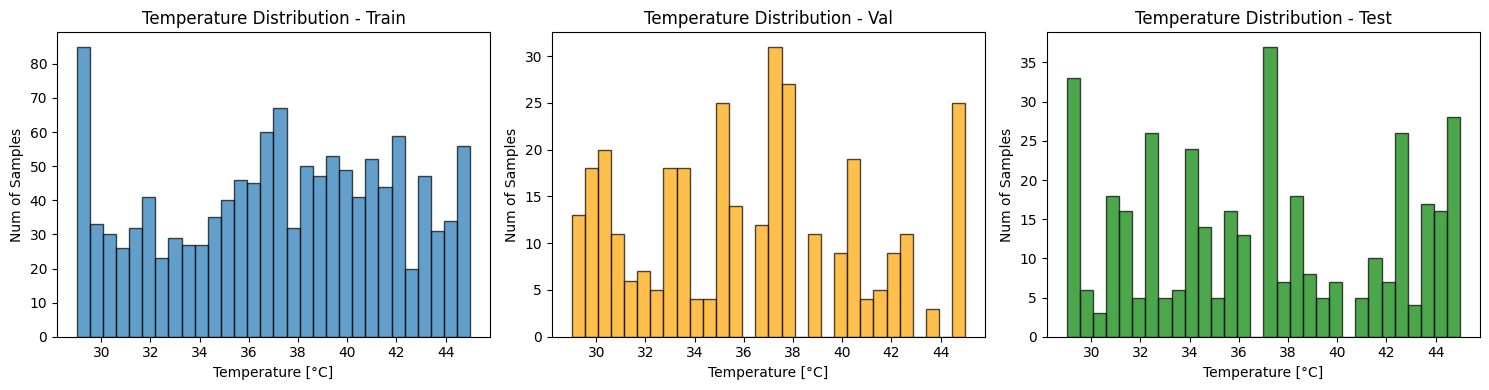

In [3]:
def extract_labels(data_loader):
    labels = []
    for _, label in data_loader:
        if isinstance(label, torch.Tensor):
            labels.extend(label.cpu().numpy())
        else:
            labels.extend(label)
    return np.array(labels)

y_train = extract_labels(train_loader)
y_val = extract_labels(val_loader)
y_test = extract_labels(test_loader)

print("Label shapes:")
print(f"  - Train: {y_train.shape}")
print(f"  - Val: {y_val.shape}")
print(f"  - Test: {y_test.shape}")

y_train = y_train.flatten()
y_val = y_val.flatten()
y_test = y_test.flatten()
print(f"\nStatistics (train):")
print(f"  - Min: {y_train.min():.2f}°C")
print(f"  - Max: {y_train.max():.2f}°C")
print(f"  - Mean: {y_train.mean():.2f}°C")
print(f"  - Median: {np.median(y_train):.2f}°C")
print(f"  - Std: {y_train.std():.2f}°C")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(y_train, bins=30, alpha=0.7, edgecolor='black')
axes[0].set_title('Temperature Distribution - Train')
axes[0].set_xlabel('Temperature [°C]')
axes[0].set_ylabel('Num of Samples')
axes[1].hist(y_val, bins=30, alpha=0.7, edgecolor='black', color='orange')
axes[1].set_title('Temperature Distribution - Val')
axes[1].set_xlabel('Temperature [°C]')
axes[1].set_ylabel('Num of Samples')
axes[2].hist(y_test, bins=30, alpha=0.7, edgecolor='black', color='green')
axes[2].set_title('Temperature Distribution - Test')
axes[2].set_xlabel('Temperature [°C]')
axes[2].set_ylabel('Num of Samples')

plt.tight_layout()
plt.savefig('../../results/baselines/data_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
train_indices, val_indices, test_indices = create_file_based_splits(
    dataset,
    test_split=config['data']['test_split'],
    val_split=config['data']['val_split'],
    random_seed=config['data']['random_seed']
)

train_val_indices = np.concatenate([train_indices, val_indices]) # we'll do GridSearchCV, val set not needed and will be used in train

print(f"\nNew size of train: {train_val_indices.size}")

X_train, y_train, groups_train = extract_features_from_indices(dataset, train_val_indices)
X_test, y_test, groups_test = extract_features_from_indices(dataset, test_indices)

X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)
X_test = np.nan_to_num(X_test, nan=0.0, posinf=0.0, neginf=0.0)

print("\nFEATURE EXTRACTION")
print(f"Shape of features:")
print(f"  - X_train: {X_train.shape}")
print(f"  - X_test: {X_test.shape}")
print(f"  - Number of features: {X_train.shape[1]}")

Total unique audio files: 333
Split results:
  Train files: 212 -> 152 slices
  Val files: 54 -> 329 slices
  Test files: 67 -> 385 slices

New size of train: 481

FEATURE EXTRACTION
Shape of features:
  - X_train: (481, 51)
  - X_test: (385, 51)
  - Number of features: 51


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
def convert_groups_to_numeric(groups):
    unique_groups = np.unique(groups)
    group_mapping = {g: i for i, g in enumerate(unique_groups)}
    return np.array([group_mapping[g] for g in groups])

## Ridge and ElasticNet Regression

In [7]:
def train_ridge_regression(X_train, y_train, groups_train):
    alpha_candidates = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

    ridge_params = {'alpha': alpha_candidates}

    if isinstance(groups_train[0], (str, np.str_)):
            groups_numeric = convert_groups_to_numeric(groups_train)
    else:
        groups_numeric = groups_train

    cv = GroupKFold(n_splits=5)
    ridge_cv = GridSearchCV(
        Ridge(),
        ridge_params,
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    ridge_cv.fit(X_train, y_train, groups=groups_numeric)

    return ridge_cv.best_estimator_, ridge_cv.best_params_, ridge_cv.best_score_

In [8]:
def train_elasticnet_regression(X_train, y_train, groups_train):
    alpha_candidates = [0.0001, 0.001, 0.01, 0.1, 1.0]
    l1_ratio_candidates = [0.1, 0.3, 0.5, 0.7, 0.9]

    elasticnet_params = {
        'alpha': alpha_candidates,
        'l1_ratio': l1_ratio_candidates
    }

    if isinstance(groups_train[0], (str, np.str_)):
            groups_numeric = convert_groups_to_numeric(groups_train)
    else:
        groups_numeric = groups_train

    cv = GroupKFold(n_splits=5)
    elasticnet_cv = GridSearchCV(
        ElasticNet(max_iter=10000, random_state=42),
        elasticnet_params,
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    elasticnet_cv.fit(X_train, y_train, groups=groups_numeric)

    return elasticnet_cv.best_estimator_, elasticnet_cv.best_params_, elasticnet_cv.best_score_

In [9]:
def plot_predictions(y_test, y_pred_ridge_test, y_pred_elasticnet_test, figsize=(14, 10)):
    ridge_test_r2 = r2_score(y_test, y_pred_ridge_test)
    ridge_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge_test))
    ridge_test_mae = mean_absolute_error(y_test, y_pred_ridge_test)

    elasticnet_test_r2 = r2_score(y_test, y_pred_elasticnet_test)
    elasticnet_test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_elasticnet_test))
    elasticnet_test_mae = mean_absolute_error(y_test, y_pred_elasticnet_test)

    fig, axes = plt.subplots(2, 2, figsize=figsize)

    # Ridge predictions
    axes[0, 0].scatter(y_test, y_pred_ridge_test, alpha=0.6, edgecolors='k', color='blue')
    axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[0, 0].set_xlabel('True Temperature [°C]')
    axes[0, 0].set_ylabel('Predicted Temperature [°C]')
    axes[0, 0].set_title(f'Ridge - Test Set\nR² = {ridge_test_r2:.4f}, RMSE = {ridge_test_rmse:.4f}, MAE = {ridge_test_mae:.4f}')
    axes[0, 0].grid(True, alpha=0.3)

    # Ridge residuals
    residuals_ridge_test = y_test - y_pred_ridge_test
    axes[0, 1].hist(residuals_ridge_test, bins=30, edgecolor='black', alpha=0.7, color='blue')
    axes[0, 1].axvline(residuals_ridge_test.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {residuals_ridge_test.mean():.4f}')
    axes[0, 1].set_xlabel('Residuals [°C]')
    axes[0, 1].set_ylabel('Frequency')
    axes[0, 1].set_title(f'Ridge - Test Residuals\nStd = {residuals_ridge_test.std():.4f}')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3, axis='y')

    # ElasticNet predictions
    axes[1, 0].scatter(y_test, y_pred_elasticnet_test, alpha=0.6, edgecolors='k', color='green')
    axes[1, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[1, 0].set_xlabel('True Temperature [°C]')
    axes[1, 0].set_ylabel('Predicted Temperature [°C]')
    axes[1, 0].set_title(f'ElasticNet - Test Set\nR² = {elasticnet_test_r2:.4f}, RMSE = {elasticnet_test_rmse:.4f}, MAE = {elasticnet_test_mae:.4f}')
    axes[1, 0].grid(True, alpha=0.3)

    # ElasticNet residuals
    residuals_elasticnet_test = y_test - y_pred_elasticnet_test
    axes[1, 1].hist(residuals_elasticnet_test, bins=30, edgecolor='black', alpha=0.7, color='green')
    axes[1, 1].axvline(residuals_elasticnet_test.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {residuals_elasticnet_test.mean():.4f}')
    axes[1, 1].set_xlabel('Residuals [°C]')
    axes[1, 1].set_ylabel('Frequency')
    axes[1, 1].set_title(f'ElasticNet - Test Residuals\nStd = {residuals_elasticnet_test.std():.4f}')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    return fig

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Ridge - Best params: {'alpha': 1.0}, CV R²: 0.1742
Fitting 5 folds for each of 25 candidates, totalling 125 fits


C:\Users\Ania\PycharmProjects\vibro-ml-v1\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.132e+02, tolerance: 1.199e+00
  model = cd_fast.enet_coordinate_descent(


ElasticNet - Best params: {'alpha': 0.001, 'l1_ratio': 0.1}, CV R²: 0.1736
        Model        R2      RMSE      MAE
0       Ridge  0.273187  4.230315  3.40169
1  ElasticNet  0.278825  4.213874  3.38116


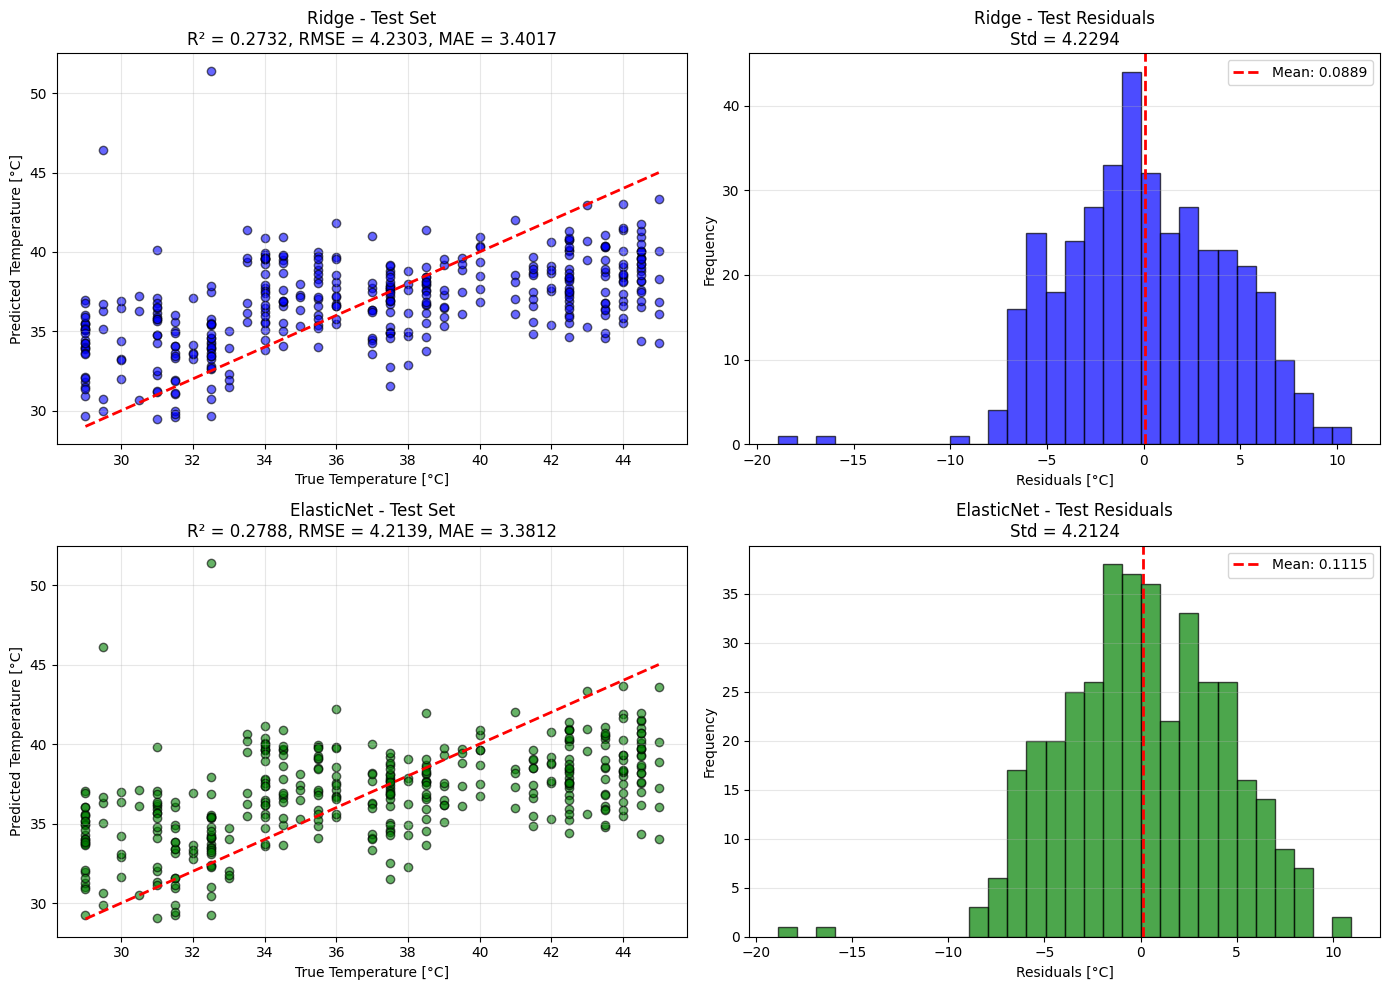

In [10]:
ridge_model, ridge_params, ridge_cv_score = train_ridge_regression(
    X_train_scaled, y_train, groups_train=groups_train
)
print(f"Ridge - Best params: {ridge_params}, CV R²: {ridge_cv_score:.4f}")

elasticnet_model, elasticnet_params, elasticnet_cv_score = train_elasticnet_regression(
    X_train_scaled, y_train, groups_train=groups_train
)
print(f"ElasticNet - Best params: {elasticnet_params}, CV R²: {elasticnet_cv_score:.4f}")

y_pred_ridge = ridge_model.predict(X_test_scaled)
y_pred_elasticnet = elasticnet_model.predict(X_test_scaled)

ridge_r2 = r2_score(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)

elasticnet_r2 = r2_score(y_test, y_pred_elasticnet)
elasticnet_rmse = np.sqrt(mean_squared_error(y_test, y_pred_elasticnet))
elasticnet_mae = mean_absolute_error(y_test, y_pred_elasticnet)

results_df = pd.DataFrame({
    'Model': ['Ridge', 'ElasticNet'],
    'R2': [ridge_r2, elasticnet_r2],
    'RMSE': [ridge_rmse, elasticnet_rmse],
    'MAE': [ridge_mae, elasticnet_mae]
})

print(results_df)
fig = plot_predictions(y_test, y_pred_ridge, y_pred_elasticnet)
plt.show()

## Support Vector Regression (SVR)

In [11]:
def train_svr(X_train, y_train, groups_train):
    kernel_candidates = ['linear', 'rbf']
    C_candidates = [0.1, 1.0, 10.0, 100.0, 1000.0]
    gamma_candidates = ['scale', 'auto']

    svr_params = {
        'kernel': kernel_candidates,
        'C': C_candidates,
        'gamma': gamma_candidates
    }

    if isinstance(groups_train[0], (str, np.str_)):
            groups_numeric = convert_groups_to_numeric(groups_train)
    else:
        groups_numeric = groups_train

    cv = GroupKFold(n_splits=5)
    svr_cv = GridSearchCV(
        SVR(),
        svr_params,
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    svr_cv.fit(X_train, y_train, groups=groups_numeric)

    return svr_cv.best_estimator_, svr_cv.best_params_, svr_cv.best_score_

In [12]:
svr_model, svr_params, svr_cv_score = train_svr(
    X_train_scaled, y_train, groups_train=groups_train
)
print(f"SVR - Best params: {svr_params}, CV R²: {svr_cv_score:.4f}")

y_pred_svr = svr_model.predict(X_test_scaled)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
SVR - Best params: {'C': 1.0, 'gamma': 'scale', 'kernel': 'linear'}, CV R²: 0.1019


In [13]:
svr_r2 = r2_score(y_test, y_pred_svr)
svr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_svr))
svr_mae = mean_absolute_error(y_test, y_pred_svr)

print(f"SVR - Test R²: {svr_r2:.4f}, RMSE: {svr_rmse:.4f}, MAE: {svr_mae:.4f}")

SVR - Test R²: 0.2028, RMSE: 4.4305, MAE: 3.5068


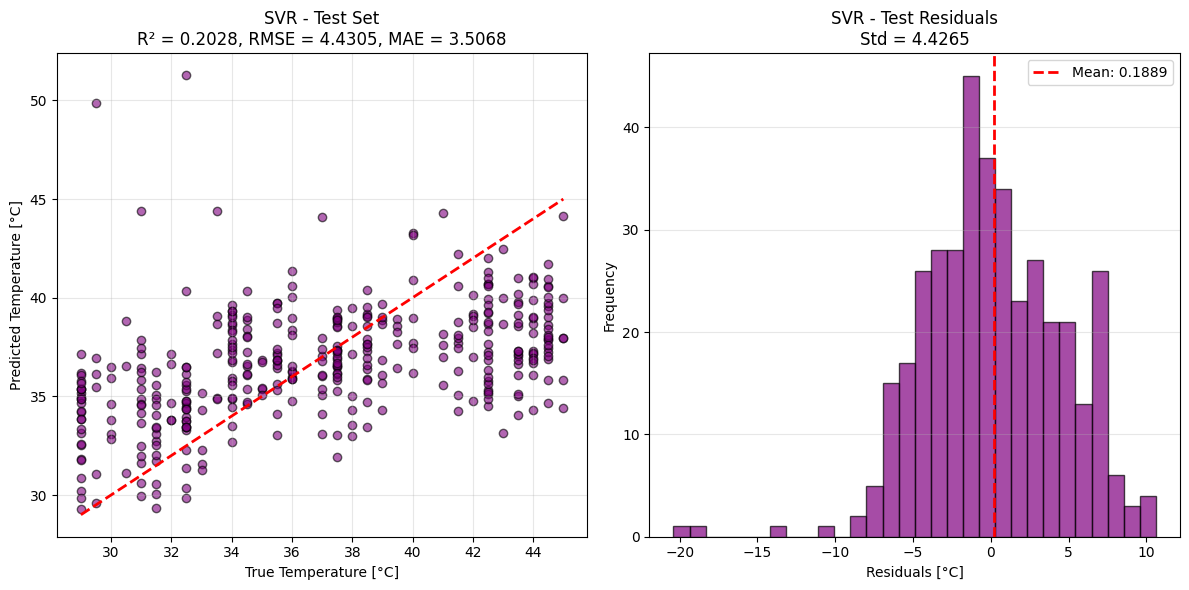

In [14]:
residuals_svr = y_test - y_pred_svr
fig, axes = plt.subplots(1, 2)
axes[0].scatter(y_test, y_pred_svr, alpha=0.6, edgecolors='k', color='purple')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('True Temperature [°C]')
axes[0].set_ylabel('Predicted Temperature [°C]')
axes[0].set_title(f'SVR - Test Set\nR² = {svr_r2:.4f}, RMSE = {svr_rmse:.4f}, MAE = {svr_mae:.4f}')
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals_svr, bins=30, edgecolor='black', alpha=0.7, color='purple')
axes[1].axvline(residuals_svr.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {residuals_svr.mean():.4f}')
axes[1].set_xlabel('Residuals [°C]')
axes[1].set_ylabel('Frequency')
axes[1].set_title(f'SVR - Test Residuals\nStd = {residuals_svr.std():.4f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../../results/baselines/svr_results.png', dpi=150, bbox_inches='tight')
plt.show()

## Random Forest Regression

In [15]:
def train_random_forest(X_train, y_train, groups_train):
    """Train Random Forest with GridSearchCV using GroupKFold CV"""

    n_estimators_candidates = [100, 200]
    max_depth_candidates = [10, 15, None]
    min_samples_split_candidates = [5, 10]
    min_samples_leaf_candidates = [2, 4]
    max_features_candidates = ['sqrt', 'log2']

    rf_params = {
        'n_estimators': n_estimators_candidates,
        'max_depth': max_depth_candidates,
        'min_samples_split': min_samples_split_candidates,
        'min_samples_leaf': min_samples_leaf_candidates,
        'max_features': max_features_candidates
    }

    if isinstance(groups_train[0], (str, np.str_)):
        groups_numeric = convert_groups_to_numeric(groups_train)
    else:
        groups_numeric = groups_train

    cv = GroupKFold(n_splits=5)
    rf_cv = GridSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=-1),
        rf_params,
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    rf_cv.fit(X_train, y_train, groups=groups_numeric)

    return rf_cv.best_estimator_, rf_cv.best_params_, rf_cv.best_score_

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Random Forest - Best params: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 200}, CV R²: -0.0104
Random Forest - Test R²: 0.1459, RMSE: 4.5859, MAE: 3.8302


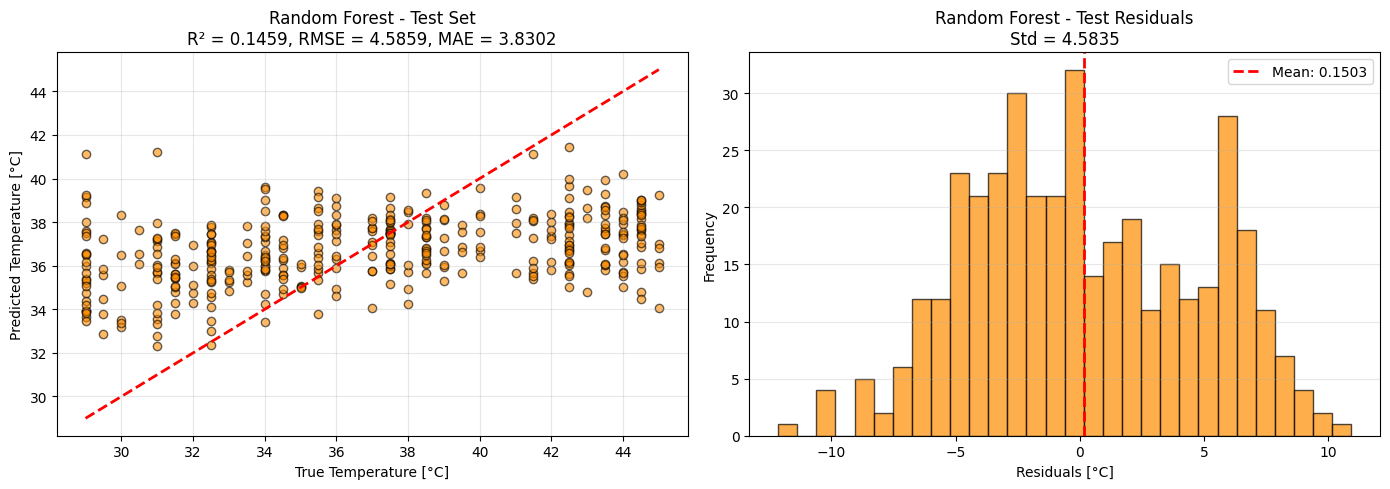

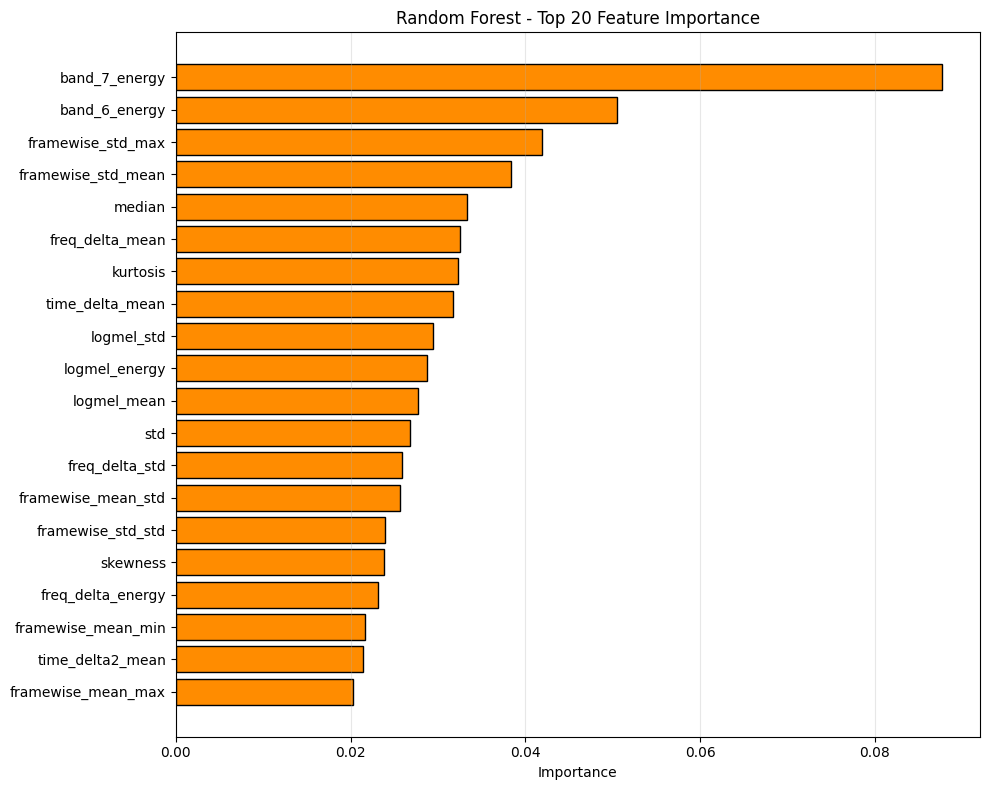

In [16]:
rf_model, rf_params, rf_cv_score = train_random_forest(X_train, y_train, groups_train=groups_train)
print(f"Random Forest - Best params: {rf_params}, CV R²: {rf_cv_score:.4f}")

y_pred_rf = rf_model.predict(X_test)
rf_r2 = r2_score(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_mae = mean_absolute_error(y_test, y_pred_rf)

print(f"Random Forest - Test R²: {rf_r2:.4f}, RMSE: {rf_rmse:.4f}, MAE: {rf_mae:.4f}")
residuals_rf = y_test - y_pred_rf
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_rf, alpha=0.6, edgecolors='k', color='darkorange')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('True Temperature [°C]')
axes[0].set_ylabel('Predicted Temperature [°C]')
axes[0].set_title(f'Random Forest - Test Set\nR² = {rf_r2:.4f}, RMSE = {rf_rmse:.4f}, MAE = {rf_mae:.4f}')
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals_rf, bins=30, edgecolor='black', alpha=0.7, color='darkorange')
axes[1].axvline(residuals_rf.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {residuals_rf.mean():.4f}')
axes[1].set_xlabel('Residuals [°C]')
axes[1].set_ylabel('Frequency')
axes[1].set_title(f'Random Forest - Test Residuals\nStd = {residuals_rf.std():.4f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../../results/baselines/rf_results.png', dpi=150, bbox_inches='tight')
plt.show()

feature_importance = rf_model.feature_importances_
feature_names = get_feature_names()
top_k = 20

top_indices = np.argsort(feature_importance)[-top_k:]
top_importance = feature_importance[top_indices]
top_names = [feature_names[i] for i in top_indices]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(len(top_names)), top_importance, color='darkorange', edgecolor='black')
ax.set_yticks(range(len(top_names)))
ax.set_yticklabels(top_names)
ax.set_xlabel('Importance')
ax.set_title(f'Random Forest - Top {top_k} Feature Importance')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('../../results/baselines/rf_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## Gradient Boosting Regression

In [17]:
def train_gradient_boosting(X_train, y_train, groups_train):
    """Train Gradient Boosting with optimized GridSearchCV"""

    n_estimators_candidates = [100, 200]
    learning_rate_candidates = [0.01, 0.1]
    max_depth_candidates = [5, 7]
    min_samples_split_candidates = [5]
    subsample_candidates = [0.8, 1.0]

    gb_params = {
        'n_estimators': n_estimators_candidates,
        'learning_rate': learning_rate_candidates,
        'max_depth': max_depth_candidates,
        'min_samples_split': min_samples_split_candidates,
        'subsample': subsample_candidates
    }

    if isinstance(groups_train[0], (str, np.str_)):
        groups_numeric = convert_groups_to_numeric(groups_train)
    else:
        groups_numeric = groups_train

    cv = GroupKFold(n_splits=5)
    gb_cv = GridSearchCV(
        GradientBoostingRegressor(random_state=42, validation_fraction=0.1),
        gb_params,
        cv=cv,
        scoring='r2',
        n_jobs=-1,
        verbose=1
    )
    gb_cv.fit(X_train, y_train, groups=groups_numeric)

    return gb_cv.best_estimator_, gb_cv.best_params_, gb_cv.best_score_

In [18]:
gb_model, gb_params, gb_cv_score = train_gradient_boosting(
    X_train, y_train, groups_train=groups_train
)
print(f"Gradient Boosting - Best params: {gb_params}, CV R²: {gb_cv_score:.4f}")

y_pred_gb = gb_model.predict(X_test)
gb_r2 = r2_score(y_test, y_pred_gb)
gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_gb))
gb_mae = mean_absolute_error(y_test, y_pred_gb)

print(f"Gradient Boosting - Test R²: {gb_r2:.4f}, RMSE: {gb_rmse:.4f}, MAE: {gb_mae:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Gradient Boosting - Best params: {'learning_rate': 0.01, 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 200, 'subsample': 0.8}, CV R²: 0.0787
Gradient Boosting - Test R²: 0.2253, RMSE: 4.3674, MAE: 3.5739


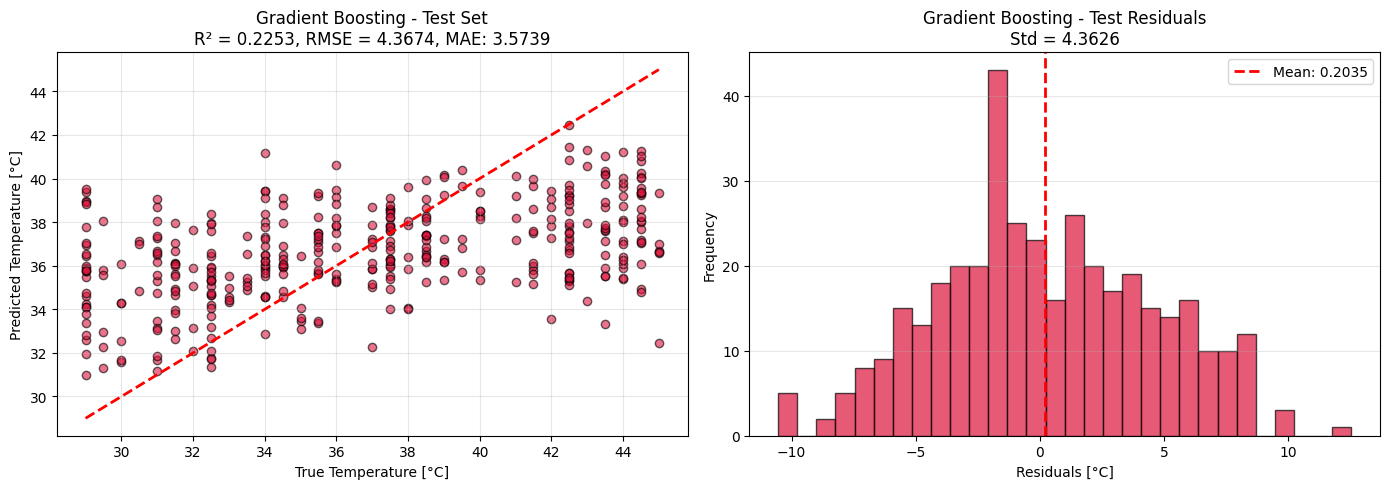

In [19]:
residuals_gb = y_test - y_pred_gb
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_gb, alpha=0.6, edgecolors='k', color='crimson')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('True Temperature [°C]')
axes[0].set_ylabel('Predicted Temperature [°C]')
axes[0].set_title(f'Gradient Boosting - Test Set\nR² = {gb_r2:.4f}, RMSE = {gb_rmse:.4f}, MAE: {gb_mae:.4f}')
axes[0].grid(True, alpha=0.3)

axes[1].hist(residuals_gb, bins=30, edgecolor='black', alpha=0.7, color='crimson')
axes[1].axvline(residuals_gb.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {residuals_gb.mean():.4f}')
axes[1].set_xlabel('Residuals [°C]')
axes[1].set_ylabel('Frequency')
axes[1].set_title(f'Gradient Boosting - Test Residuals\nStd = {residuals_gb.std():.4f}')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../../results/baselines/gb_results.png', dpi=150, bbox_inches='tight')
plt.show()

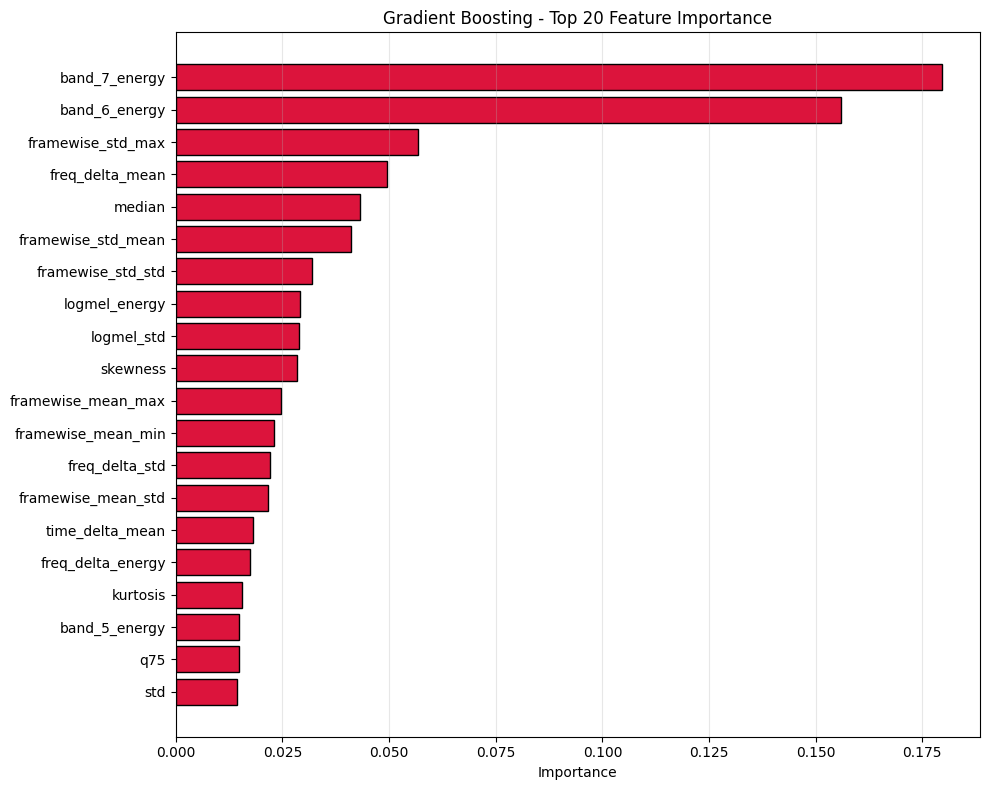

In [20]:
feature_importance_gb = gb_model.feature_importances_
feature_names = get_feature_names()
top_k = 20

top_indices = np.argsort(feature_importance_gb)[-top_k:]
top_importance = feature_importance_gb[top_indices]
top_names = [feature_names[i] for i in top_indices]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(len(top_names)), top_importance, color='crimson', edgecolor='black')
ax.set_yticks(range(len(top_names)))
ax.set_yticklabels(top_names)
ax.set_xlabel('Importance')
ax.set_title(f'Gradient Boosting - Top {top_k} Feature Importance')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('../../results/baselines/gb_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary of Results

Best model by R²: ElasticNet (R² = 0.2788)
Best model by RMSE: ElasticNet (RMSE = 4.2139°C)
Best model by MAE: ElasticNet (MAE = 3.3812°C)


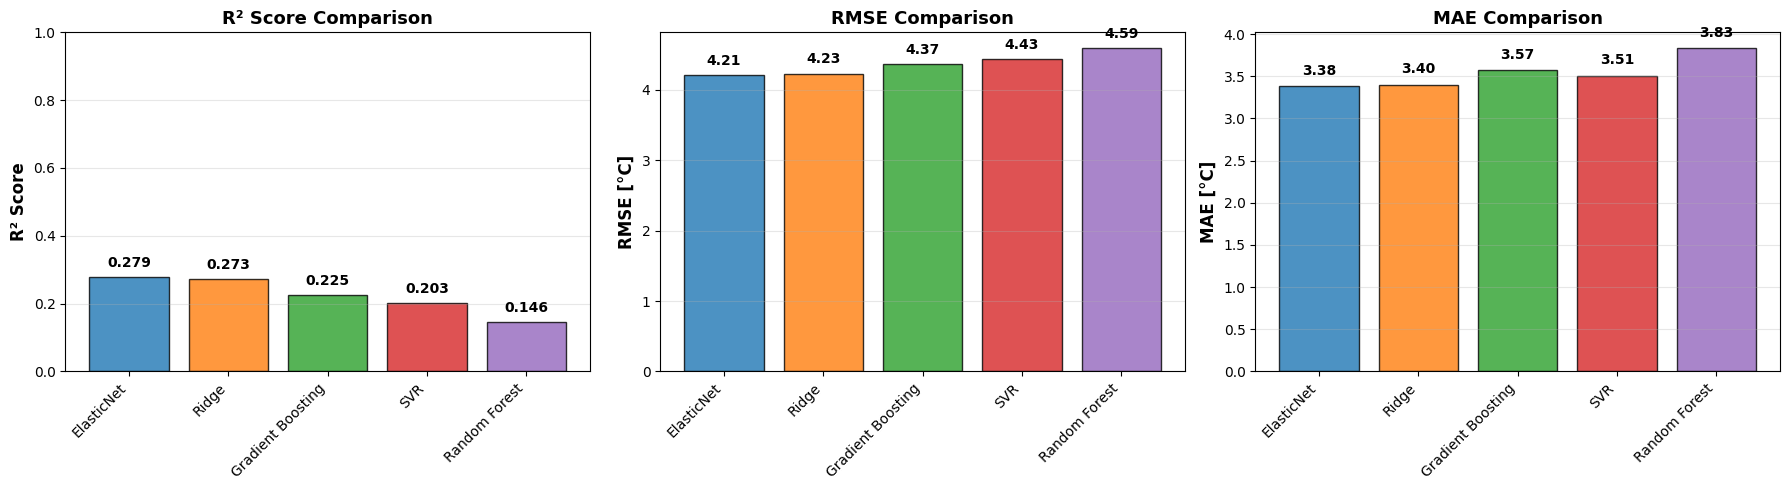

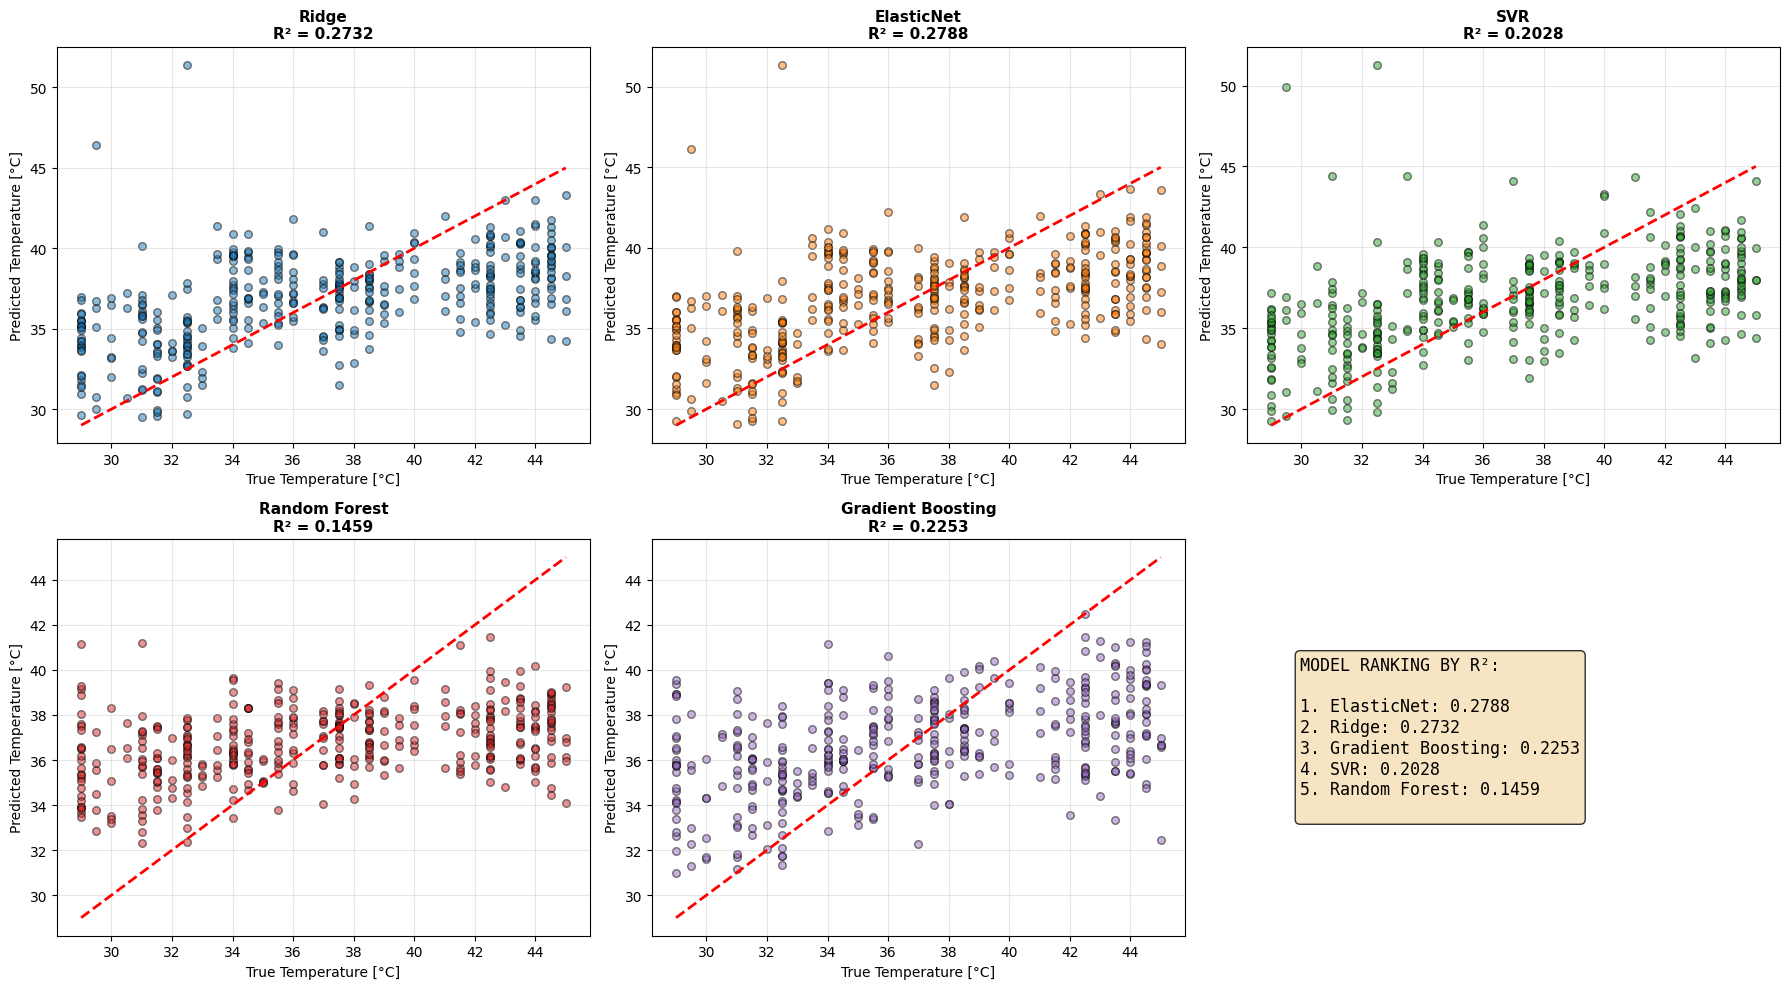

In [25]:
results_comparison = pd.DataFrame({
    'Model': ['Ridge', 'ElasticNet', 'SVR', 'Random Forest', 'Gradient Boosting'],
    'R²': [ridge_r2, elasticnet_r2, svr_r2, rf_r2, gb_r2],
    'RMSE [°C]': [ridge_rmse, elasticnet_rmse, svr_rmse, rf_rmse, gb_rmse],
    'MAE [°C]': [ridge_mae, elasticnet_mae, svr_mae, rf_mae, gb_mae]
})

results_comparison = results_comparison.sort_values('R²', ascending=False).reset_index(drop=True)

print(f"Best model by R²: {results_comparison.iloc[0]['Model']} (R² = {results_comparison.iloc[0]['R²']:.4f})")
print(
    f"Best model by RMSE: {results_comparison.loc[results_comparison['RMSE [°C]'].idxmin(), 'Model']} (RMSE = {results_comparison['RMSE [°C]'].min():.4f}°C)")
print(
    f"Best model by MAE: {results_comparison.loc[results_comparison['MAE [°C]'].idxmin(), 'Model']} (MAE = {results_comparison['MAE [°C]'].min():.4f}°C)")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
model_names = results_comparison['Model'].values

axes[0].bar(range(len(model_names)), results_comparison['R²'].values, color=colors, edgecolor='black', alpha=0.8)
axes[0].set_ylabel('R² Score', fontsize=12, fontweight='bold')
axes[0].set_title('R² Score Comparison', fontsize=13, fontweight='bold')
axes[0].set_xticks(range(len(model_names)))
axes[0].set_xticklabels(model_names, rotation=45, ha='right')
axes[0].set_ylim([0, 1])
axes[0].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(results_comparison['R²'].values):
    axes[0].text(i, v + 0.02, f'{v:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

axes[1].bar(range(len(model_names)), results_comparison['RMSE [°C]'].values, color=colors, edgecolor='black', alpha=0.8)
axes[1].set_ylabel('RMSE [°C]', fontsize=12, fontweight='bold')
axes[1].set_title('RMSE Comparison', fontsize=13, fontweight='bold')
axes[1].set_xticks(range(len(model_names)))
axes[1].set_xticklabels(model_names, rotation=45, ha='right')
axes[1].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(results_comparison['RMSE [°C]'].values):
    axes[1].text(i, v + 0.1, f'{v:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

axes[2].bar(range(len(model_names)), results_comparison['MAE [°C]'].values, color=colors, edgecolor='black', alpha=0.8)
axes[2].set_ylabel('MAE [°C]', fontsize=12, fontweight='bold')
axes[2].set_title('MAE Comparison', fontsize=13, fontweight='bold')
axes[2].set_xticks(range(len(model_names)))
axes[2].set_xticklabels(model_names, rotation=45, ha='right')
axes[2].grid(True, alpha=0.3, axis='y')
for i, v in enumerate(results_comparison['MAE [°C]'].values):
    axes[2].text(i, v + 0.1, f'{v:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('../../results/baselines/all_models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

predictions_all = [y_pred_ridge, y_pred_elasticnet, y_pred_svr, y_pred_rf, y_pred_gb]
model_names = ['Ridge', 'ElasticNet', 'SVR', 'Random Forest', 'Gradient Boosting']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
r2_scores = [ridge_r2, elasticnet_r2, svr_r2, rf_r2, gb_r2]

for idx, (ax, predictions, model_name, color, r2) in enumerate(
        zip(axes[:-1], predictions_all, model_names, colors, r2_scores)):
    ax.scatter(y_test, predictions, alpha=0.5, edgecolors='k', color=color, s=30)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_xlabel('True Temperature [°C]', fontsize=10)
    ax.set_ylabel('Predicted Temperature [°C]', fontsize=10)
    ax.set_title(f'{model_name}\nR² = {r2:.4f}', fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)

axes[-1].axis('off')
legend_text = "MODEL RANKING BY R²:\n\n"
for i, row in results_comparison.iterrows():
    legend_text += f"{i + 1}. {row['Model']}: {row['R²']:.4f}\n"
axes[-1].text(0.1, 0.5, legend_text, fontsize=12, verticalalignment='center',
              bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8), family='monospace')

plt.tight_layout()
plt.savefig('../../results/baselines/predictions_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


results_comparison.to_csv('../../results/baselines/all_models_results.csv', index=False)